In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU não disponível.")

In [1]:
from google.colab import files

uploaded = files.upload()

Saving reviews_cleaned.csv to reviews_cleaned.csv


In [2]:
import pandas as pd

df = pd.read_csv("reviews_cleaned.csv", encoding="utf-8")

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nSentiment distribution:")
print(df["Sentiment"].value_counts())

print("\nMissing values:")
print(df[["review_text", "Sentiment"]].isnull().sum())

print("\nSample reviews:")
display(df[["review_text", "Sentiment"]].head())

Dataset shape: (42370, 9)

Columns:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp', 'review_text', 'Sentiment']

Sentiment distribution:
Sentiment
positive    27895
negative    10861
neutral      3614
Name: count, dtype: int64

Missing values:
review_text    0
Sentiment      0
dtype: int64

Sample reviews:


,review_text,Sentiment
0,Recebi bem antes do prazo estipulado.,positive
1,Parabéns lojas lannister adorei comprar pela I...,positive
2,recomendo aparelho eficiente. no site a marca ...,positive
3,"Mas um pouco ,travando...pelo valor ta Boa.",positive
4,"Super recomendo Vendedor confiável, produto ok...",positive


In [3]:
from sklearn.model_selection import train_test_split

X = df["review_text"]
y = df["Sentiment"]

# First split: training and test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Second split: training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.1,
    random_state=42,
    stratify=y_train_full
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 30506
Validation samples: 3390
Testing samples: 8474

Training distribution:
Sentiment
positive    0.658
negative    0.256
neutral     0.085
Name: proportion, dtype: float64

Validation distribution:
Sentiment
positive    0.658
negative    0.256
neutral     0.085
Name: proportion, dtype: float64

Testing distribution:
Sentiment
positive    0.658
negative    0.256
neutral     0.085
Name: proportion, dtype: float64


In [4]:
!pip -q install transformers datasets accelerate


In [5]:
from transformers import AutoTokenizer

MODEL_NAME = "neuralmind/bert-base-portuguese-cased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Model:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizer loaded successfully!
Model: neuralmind/bert-base-portuguese-cased
Vocabulary size: 29794


In [6]:
MAX_LENGTH = 128

train_encodings = tokenizer(
    X_train.tolist(),
    truncation=True,
    max_length=MAX_LENGTH
)

val_encodings = tokenizer(
    X_val.tolist(),
    truncation=True,
    max_length=MAX_LENGTH
)

test_encodings = tokenizer(
    X_test.tolist(),
    truncation=True,
    max_length=MAX_LENGTH
)

print("Tokenization completed!")

print("Training samples:", len(train_encodings["input_ids"]))
print("Validation samples:", len(val_encodings["input_ids"]))
print("Testing samples:", len(test_encodings["input_ids"]))

print("\nExample tokenized review:")
print(train_encodings["input_ids"][0])

Tokenization completed!
Training samples: 30506
Validation samples: 3390
Testing samples: 8474

Example tokenized review:
[101, 3174, 124, 229, 9358, 548, 22282, 146, 2182, 346, 2663, 22283, 7343, 5634, 106, 102]


In [7]:
label2id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

id2label = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

y_train_encoded = y_train.map(label2id).tolist()
y_val_encoded = y_val.map(label2id).tolist()
y_test_encoded = y_test.map(label2id).tolist()

print("Label mapping:", label2id)
print("First 10 encoded labels:", y_train_encoded[:10])

Label mapping: {'negative': 0, 'neutral': 1, 'positive': 2}
First 10 encoded labels: [0, 0, 2, 2, 0, 2, 1, 2, 0, 1]


In [8]:
import torch
from torch.utils.data import Dataset

class ReviewDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return item


train_dataset = ReviewDataset(train_encodings, y_train_encoded)
val_dataset = ReviewDataset(val_encodings, y_val_encoded)
test_dataset = ReviewDataset(test_encodings, y_test_encoded)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

print("\nExample item:")
print(train_dataset[0])

Training dataset: 30506
Validation dataset: 3390
Testing dataset: 8474

Example item:
{'input_ids': tensor([  101,  3174,   124,   229,  9358,   548, 22282,   146,  2182,   346,
         2663, 22283,  7343,  5634,   106,   102]), 'token_type_ids': tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'attention_mask': tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]), 'labels': tensor(0)}


In [9]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("BERTimbau loaded successfully!")
print("Number of labels:", model.config.num_labels)
print("Labels:", model.config.id2label)
print("GPU available:", torch.cuda.is_available())

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

BERTimbau loaded successfully!
Number of labels: 3
Labels: {0: 'negative', 1: 'neutral', 2: 'positive'}
GPU available: True


In [11]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Data collator configured successfully!")

Data collator configured successfully!


In [12]:
import transformers
import torch

print("Transformers version:", transformers.__version__)
print("PyTorch version:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

Transformers version: 5.22.1
PyTorch version: 2.14.1+cu130
GPU: Tesla T4


In [13]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
        "weighted_f1": f1_score(labels, predictions, average="weighted"),
        "macro_precision": precision_score(labels, predictions, average="macro"),
        "macro_recall": recall_score(labels, predictions, average="macro")
    }

print("Evaluation metrics configured successfully!")

Evaluation metrics configured successfully!


In [14]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./bertimbau-results",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    report_to="none",
    fp16=True,
    seed=42
)

print("Training configuration created successfully!")

Training configuration created successfully!


In [15]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1, 2])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.array(y_train_encoded)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)

print("Class weights:")
for label, weight in zip(classes, class_weights):
    print(f"{id2label[label]}: {weight.item():.4f}")

Class weights:
negative: 1.3003
neutral: 3.9080
positive: 0.5063


In [16]:
import torch.nn.functional as F

def weighted_loss(outputs, labels, num_items_in_batch=None):
    logits = outputs.logits

    loss = F.cross_entropy(
        logits,
        labels,
        weight=class_weights.to(logits.device)
    )

    return loss

print("Weighted loss configured successfully!")

Weighted loss configured successfully!


In [17]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    compute_loss_func=weighted_loss,
    processing_class=tokenizer
)

print("Trainer configured successfully!")

Trainer configured successfully!


In [18]:
training_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall
1,0.611388,0.603372,0.846313,0.710698,0.858371,0.698762,0.733133
2,0.539691,0.680085,0.859882,0.713866,0.864802,0.705124,0.724807
3,0.523491,0.771153,0.856047,0.718674,0.863584,0.708402,0.733945


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [19]:
test_results = trainer.evaluate(test_dataset)

print("\nFinal Test Results:")

for metric, value in test_results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall
0.523491,0.845550,3,0.843639,0.693530,0.851004,0.686012,0.704549



Final Test Results:
eval_loss: 0.8455
eval_accuracy: 0.8436
eval_macro_f1: 0.6935
eval_weighted_f1: 0.8510
eval_macro_precision: 0.6860
eval_macro_recall: 0.7045


In [20]:
from sklearn.metrics import classification_report

predictions_output = trainer.predict(test_dataset)

y_pred_bert = np.argmax(
    predictions_output.predictions,
    axis=1
)

y_test_bert = np.array(y_test_encoded)

print(classification_report(
    y_test_bert,
    y_pred_bert,
    labels=[0, 1, 2],
    target_names=["negative", "neutral", "positive"],
    digits=4
))

              precision    recall  f1-score   support

    negative     0.8300    0.8522    0.8410      2172
     neutral     0.2815    0.3582    0.3153       723
    positive     0.9465    0.9032    0.9243      5579

    accuracy                         0.8436      8474
   macro avg     0.6860    0.7045    0.6935      8474
weighted avg     0.8599    0.8436    0.8510      8474



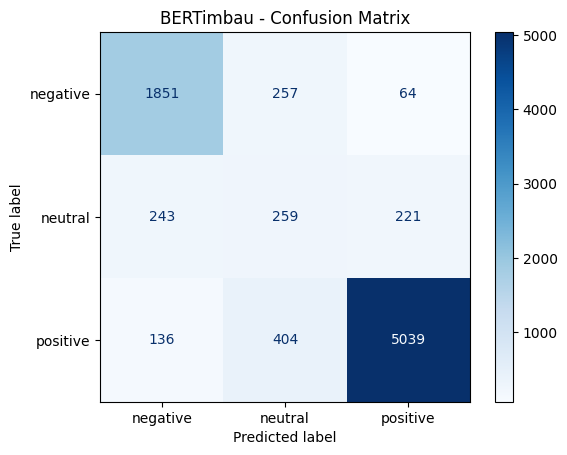

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test_bert,
    y_pred_bert,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["negative", "neutral", "positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("BERTimbau - Confusion Matrix")
plt.show()

In [22]:
from pathlib import Path

MODEL_OUTPUT_DIR = "./models/bertimbau-sentiment"

Path(MODEL_OUTPUT_DIR).mkdir(
    parents=True,
    exist_ok=True
)

trainer.save_model(MODEL_OUTPUT_DIR)
tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

print("Model and tokenizer saved successfully!")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved successfully!


In [23]:
import os

print("Saved files:")
for file in os.listdir(MODEL_OUTPUT_DIR):
    print(file)

Saved files:
tokenizer.json
config.json
tokenizer_config.json
training_args.bin
model.safetensors


In [24]:
model_card = """
---
language:
- pt
license: cc-by-nc-sa-4.0
library_name: transformers
pipeline_tag: text-classification
tags:
- bert
- bertimbau
- sentiment-analysis
- portuguese
- nlp
---

# BERTimbau — Brazilian Portuguese Sentiment Classification

## Overview

This model performs three-class sentiment classification
of Brazilian Portuguese customer reviews.

It was fine-tuned from:
`neuralmind/bert-base-portuguese-cased`

## Classes

- 0: negative
- 1: neutral
- 2: positive

## Dataset

The model was trained using customer reviews from the
Brazilian Olist e-commerce dataset.

Sentiment labels were derived from review scores:

- Scores 1–2: negative
- Score 3: neutral
- Scores 4–5: positive

These are weak labels derived from numerical ratings,
not independent human annotations of review text.

## Training

- Architecture: BERTimbau
- Maximum sequence length: 128
- Epochs: 3
- Learning rate: 2e-5
- Training samples: 30,506
- Validation samples: 3,390
- Test samples: 8,474
- Hardware: NVIDIA Tesla T4

## Test Results

| Metric | Score |
|---|---:|
| Accuracy | 0.8436 |
| Macro F1 | 0.6935 |
| Weighted F1 | 0.8510 |
| Macro Precision | 0.6860 |
| Macro Recall | 0.7045 |

### Per-class F1

| Class | F1 |
|---|---:|
| Negative | 0.8410 |
| Neutral | 0.3153 |
| Positive | 0.9243 |

## Limitations

The neutral class remains challenging.

The dataset contains imbalanced classes, and labels
were derived from review scores rather than manual
sentiment annotation.

The model was trained on Brazilian e-commerce reviews
and should not be assumed to generalize to every
Portuguese text domain.

## Intended Use

Research and experimentation in Portuguese NLP,
sentiment analysis, and machine learning.

## Base Model

neuralmind/bert-base-portuguese-cased

## Dataset Attribution

Olist Brazilian E-Commerce Public Dataset:
https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

Review the dataset's CC BY-NC-SA 4.0 license terms
before redistributing or using derived artifacts.
"""

with open(f"{MODEL_OUTPUT_DIR}/README.md", "w", encoding="utf-8") as f:
    f.write(model_card)

print("Model card created successfully!")

Model card created successfully!


In [25]:
with open(f"{MODEL_OUTPUT_DIR}/README.md", encoding="utf-8") as f:
    print(f.read()[:1500])


---
language:
- pt
license: cc-by-nc-sa-4.0
library_name: transformers
pipeline_tag: text-classification
tags:
- bert
- bertimbau
- sentiment-analysis
- portuguese
- nlp
---

# BERTimbau — Brazilian Portuguese Sentiment Classification

## Overview

This model performs three-class sentiment classification
of Brazilian Portuguese customer reviews.

It was fine-tuned from:
`neuralmind/bert-base-portuguese-cased`

## Classes

- 0: negative
- 1: neutral
- 2: positive

## Dataset

The model was trained using customer reviews from the
Brazilian Olist e-commerce dataset.

Sentiment labels were derived from review scores:

- Scores 1–2: negative
- Score 3: neutral
- Scores 4–5: positive

These are weak labels derived from numerical ratings,
not independent human annotations of review text.

## Training

- Architecture: BERTimbau
- Maximum sequence length: 128
- Epochs: 3
- Learning rate: 2e-5
- Training samples: 30,506
- Validation samples: 3,390
- Test samples: 8,474
- Hardware: NVIDIA Tesla 

In [26]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [27]:
import shutil

backup_path = "/content/drive/MyDrive/bertimbau-sentiment"

shutil.copytree(
    MODEL_OUTPUT_DIR,
    backup_path,
    dirs_exist_ok=True
)

print("Backup completed!")

Backup completed!


In [28]:
import shutil

shutil.make_archive(
    "/content/bertimbau-sentiment",
    "zip",
    "/content/drive/MyDrive/bertimbau-sentiment"
)

from google.colab import files
files.download("/content/bertimbau-sentiment.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>